In [1]:
%pip install --upgrade protobuf

Note: you may need to restart the kernel to use updated packages.


In [9]:
import tensorflow as tf
from keras.models import Sequential
from keras.datasets import mnist
import matplotlib.pyplot as plt
import random
import numpy as np


In [10]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train=x_train/255
x_test=x_test/255

In [11]:
from keras.src.models import sequential
import keras
model=Sequential()
model.add(keras.layers.Flatten(input_shape=(28,28)))
model.add(keras.layers.Dense(128,activation='relu'))
model.add(keras.layers.Dense(10,activation='softmax'))

In [12]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 406us/step - accuracy: 0.8376 - loss: 0.6434 - val_accuracy: 0.9012 - val_loss: 0.3614
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 377us/step - accuracy: 0.9044 - loss: 0.3400 - val_accuracy: 0.9176 - val_loss: 0.2965
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 428us/step - accuracy: 0.9173 - loss: 0.2933 - val_accuracy: 0.9252 - val_loss: 0.2674
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 378us/step - accuracy: 0.9252 - loss: 0.2645 - val_accuracy: 0.9312 - val_loss: 0.2434
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 373us/step - accuracy: 0.9323 - loss: 0.2420 - val_accuracy: 0.9348 - val_loss: 0.2265


In [13]:
test_loss ,test_acc=model.evaluate(x_test,y_test)
print("Loss=%.3f" %test_loss)
print("Accuracy=%.3f" %test_acc)


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 287us/step - accuracy: 0.9348 - loss: 0.2265
Loss=0.226
Accuracy=0.935


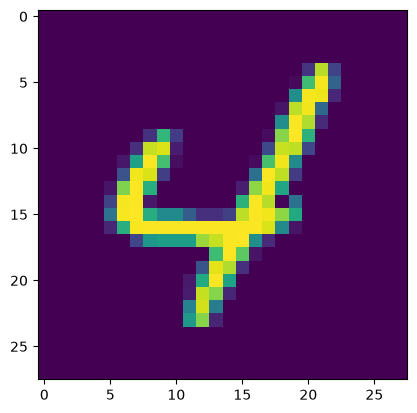

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 239us/step
The handwritten number in image is 4


In [14]:
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()
prediction=model.predict(x_test)
print("The handwritten number in image is %d" %np.argmax(prediction[n]))

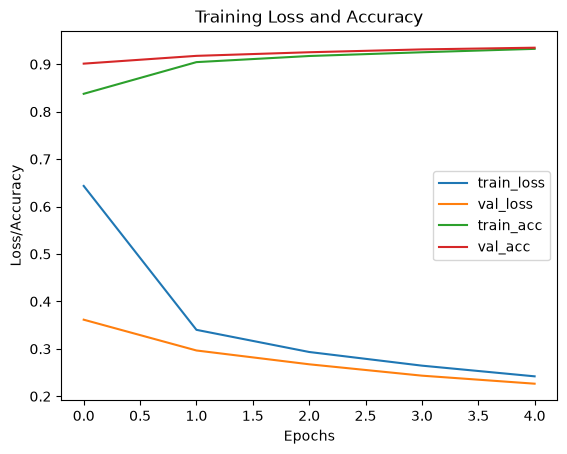

In [15]:
import matplotlib.pyplot as plt

plt.plot(H.history['loss'], label='train_loss')
plt.plot(H.history['val_loss'], label='val_loss')
plt.plot(H.history['accuracy'], label='train_acc')
plt.plot(H.history['val_accuracy'], label='val_acc')

plt.title('Training Loss and Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss/Accuracy')
plt.legend()

plt.show()